# 02 Features

The feature tables built by `build_features`: which features follow bearing wear in FEMTO and IMS, and whether the fault frequency features separate the fault types in SCA.

### Setup and loading the feature tables

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED = Path("data/processed")
femto = pd.read_parquet(PROCESSED / "features_femto.parquet")
ims = pd.read_parquet(PROCESSED / "features_ims.parquet")
sca = pd.read_parquet(PROCESSED / "features_sca.parquet")
label_names = {-1: "off or no speed", 0: "normal", 1: "inner ring", 2: "ball", 3: "outer ring"}

pd.DataFrame(
    {"rows": [len(femto), len(ims), len(sca)], "columns": [femto.shape[1], ims.shape[1], sca.shape[1]]},
    index=["FEMTO", "IMS", "SCA"],
)

,rows,columns
FEMTO,24889,44
IMS,37844,59
SCA,6644,29


### Feature names per channel

In [2]:
sorted({c.split("_", 1)[1] for c in femto.columns if c.startswith("horizontal_")})

['band1_share',
 'band2_share',
 'band3_share',
 'band4_share',
 'centroid_hz',
 'crest',
 'dominant_hz',
 'fault_BPF',
 'fault_BPFI',
 'fault_BPFO',
 'fault_FTF',
 'flat_top_fraction',
 'kurtosis',
 'mean',
 'peak',
 'rms',
 'skewness',
 'std']

## FEMTO: features over the life of each bearing

Life fraction is 0 at the first recording and 1 at the last one, so bearings with different lifetimes can be compared.

### FEMTO life fraction

In [3]:
femto["life_fraction"] = femto.groupby("bearing")["seconds"].transform(lambda s: s / s.max())
femto[["bearing", "recording", "seconds", "life_fraction"]].head()

,bearing,recording,seconds,life_fraction
0,Bearing1_1,1,0.0,0.000000
1,Bearing1_1,2,10.0,0.000357
2,Bearing1_1,3,20.0,0.000714
3,Bearing1_1,4,30.0,0.001071
4,Bearing1_1,5,40.0,0.001428


### FEMTO selected features over the fraction of life

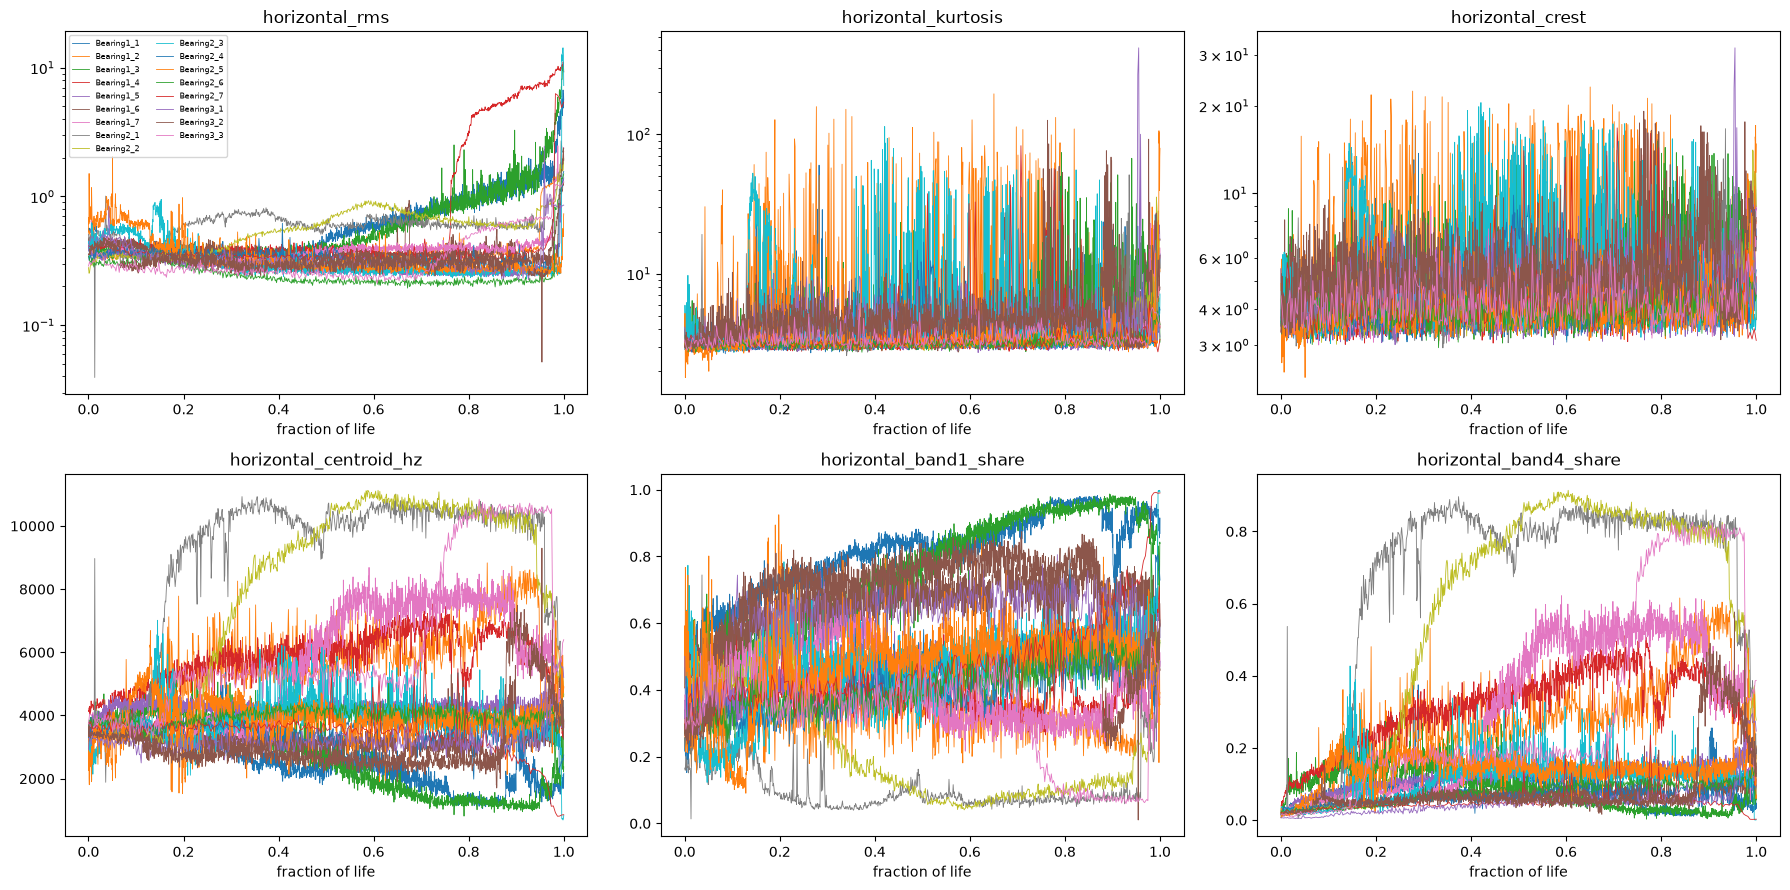

In [4]:
selected = ["rms", "kurtosis", "crest", "centroid_hz", "band1_share", "band4_share"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, name in zip(axes.flat, selected):
    for bearing, g in femto.groupby("bearing"):
        ax.plot(g["life_fraction"], g[f"horizontal_{name}"], lw=0.6, label=bearing)
    ax.set_title(f"horizontal_{name}")
    ax.set_xlabel("fraction of life")
    if name in ("rms", "kurtosis", "crest"):
        ax.set_yscale("log")
axes.flat[0].legend(fontsize=6, ncol=2)
plt.tight_layout()

### FEMTO features that follow the wear

In [5]:
# Spearman correlation between each feature and the fraction of life, computed per bearing.
names = [c for c in femto.columns if c.startswith(("horizontal_", "vertical_")) and "_fault_" not in c]
per_bearing = femto.groupby("bearing")[names + ["life_fraction"]].apply(
    lambda g: g[names].corrwith(g["life_fraction"], method="spearman")
)
pd.DataFrame(
    {"median": per_bearing.median(), "lowest": per_bearing.min(), "highest": per_bearing.max()}
).sort_values("median", ascending=False).round(2)

,median,lowest,highest
horizontal_band4_share,0.68,-0.79,0.90
vertical_centroid_hz,0.58,-0.71,0.84
vertical_band4_share,0.52,-0.76,0.86
horizontal_band1_share,0.47,-0.65,0.94
vertical_kurtosis,0.38,-0.18,0.81
horizontal_kurtosis,0.37,-0.08,0.84
vertical_band3_share,0.35,-0.71,0.93
horizontal_band3_share,0.31,-0.86,0.87
vertical_crest,0.26,-0.16,0.75
horizontal_crest,0.26,-0.07,0.70


### FEMTO peak and flat-top fraction at the sensor limit

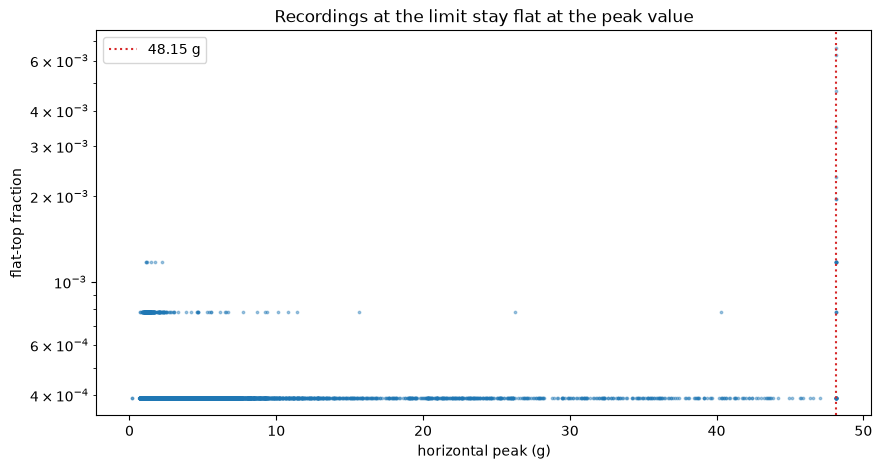

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(femto["horizontal_peak"], femto["horizontal_flat_top_fraction"], s=3, alpha=0.4)
ax.axvline(48.15, color="tab:red", ls=":", label="48.15 g")
ax.set_xlabel("horizontal peak (g)")
ax.set_ylabel("flat-top fraction")
ax.set_yscale("log")
ax.set_title("Recordings at the limit stay flat at the peak value")
ax.legend()

## IMS: failed and healthy bearings

Solid lines are the bearings that failed at the end of a test, dotted lines the others. Test 1 shows the x channel.

### IMS RMS per bearing

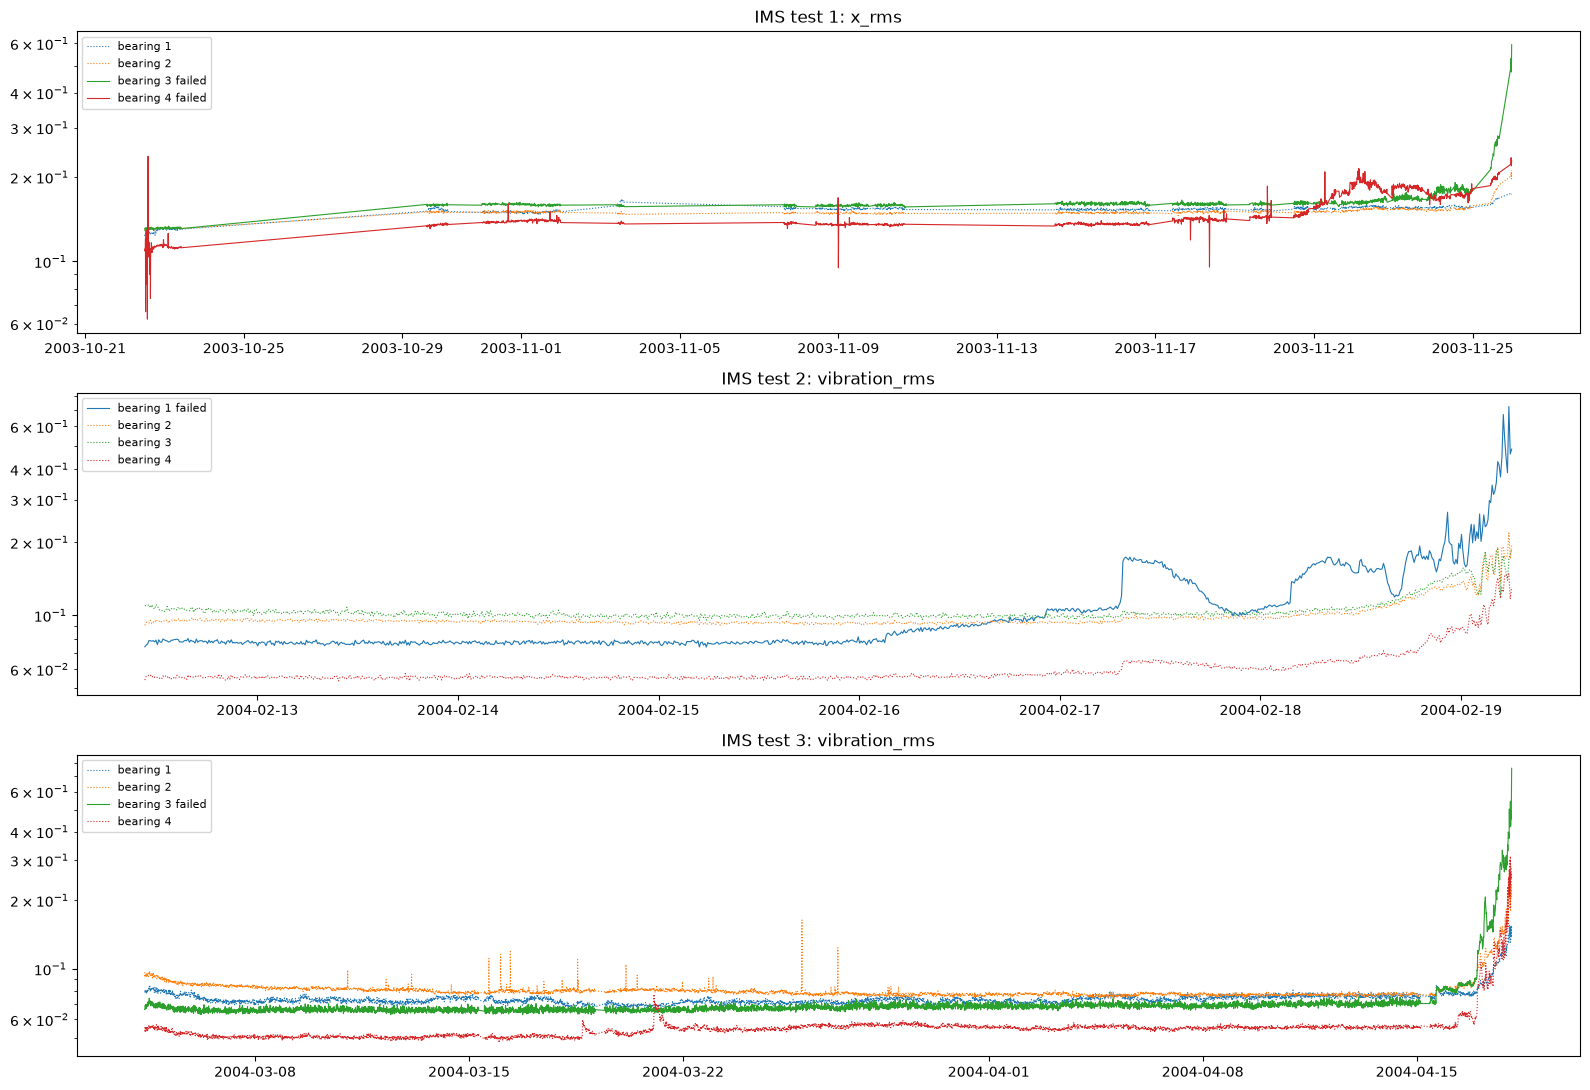

In [7]:
def plot_ims(feature: str) -> None:
    fig, axes = plt.subplots(3, 1, figsize=(16, 11))
    for ax, (test, g) in zip(axes, ims.groupby("test")):
        column = f"x_{feature}" if test == 1 else f"vibration_{feature}"
        for bearing, gb in g.groupby("bearing"):
            failed = gb["failed"].iat[0]
            ax.plot(gb["time"], gb[column], "-" if failed else ":", lw=0.8,
                    label=f"bearing {bearing}" + (" failed" if failed else ""))
        ax.set_title(f"IMS test {test}: {column}")
        ax.set_yscale("log")
        ax.legend(fontsize=8)
    plt.tight_layout()


plot_ims("rms")

### IMS kurtosis per bearing

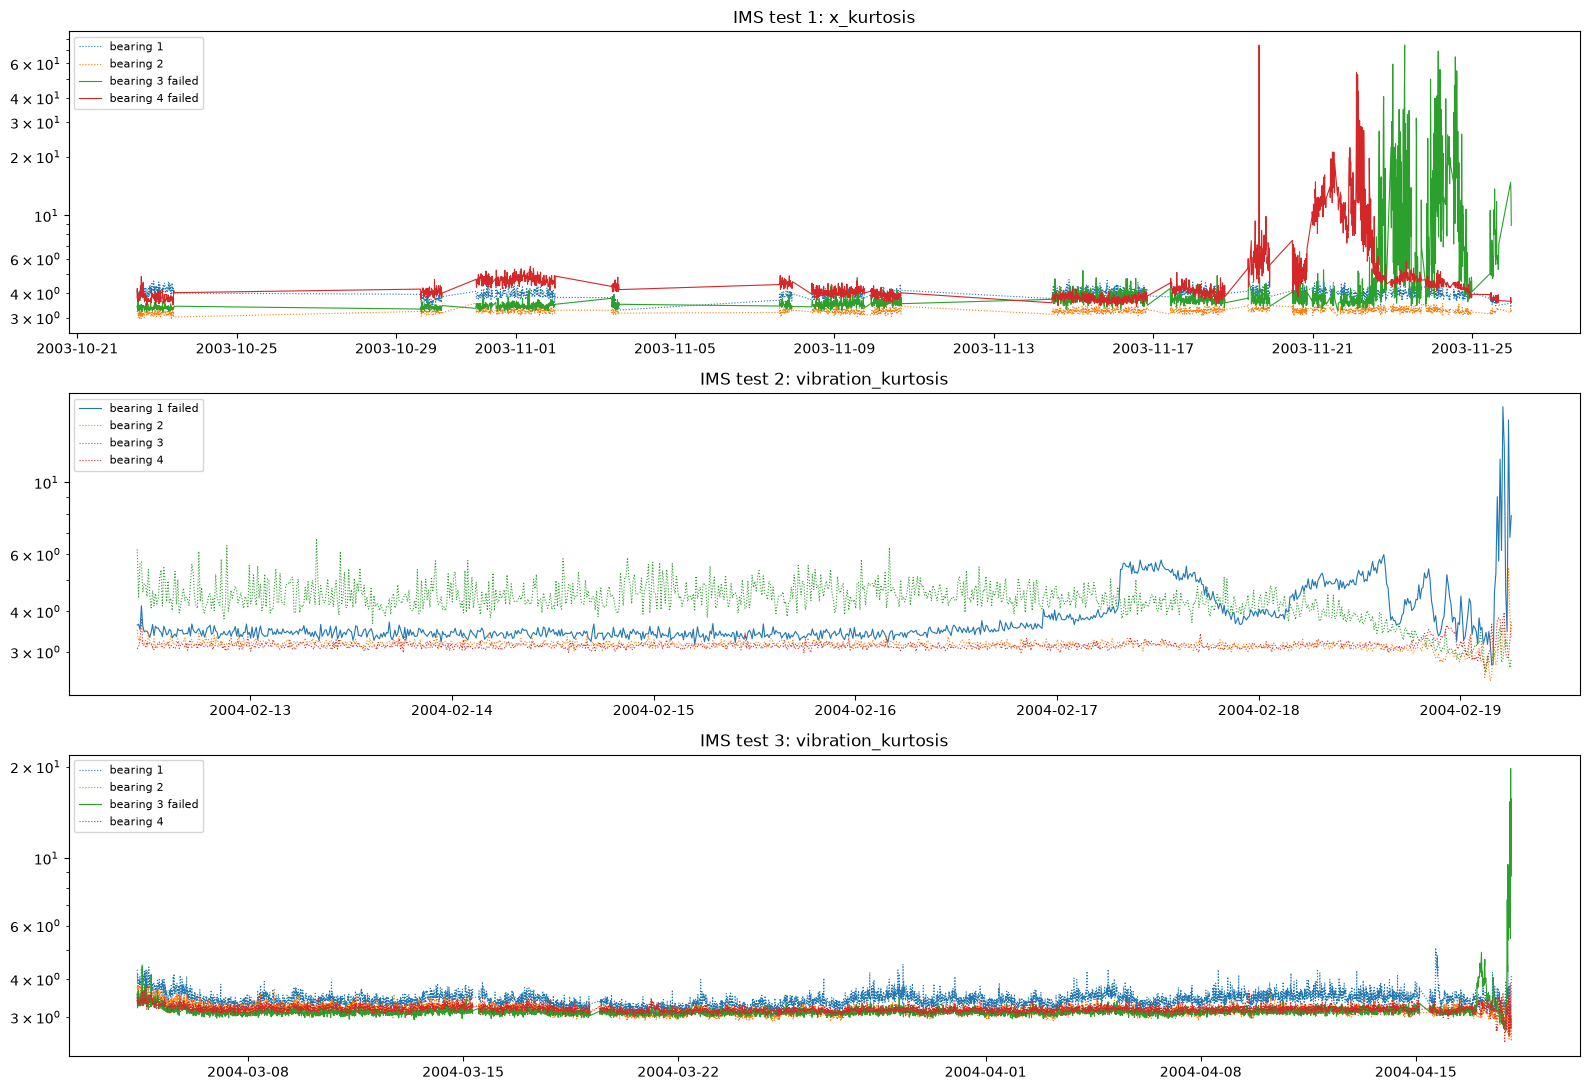

In [8]:
plot_ims("kurtosis")

## SCA: fault frequency features in the pulp mill

Only measurements with a known shaft speed are used, since the fault features need it.

### SCA fault features by label

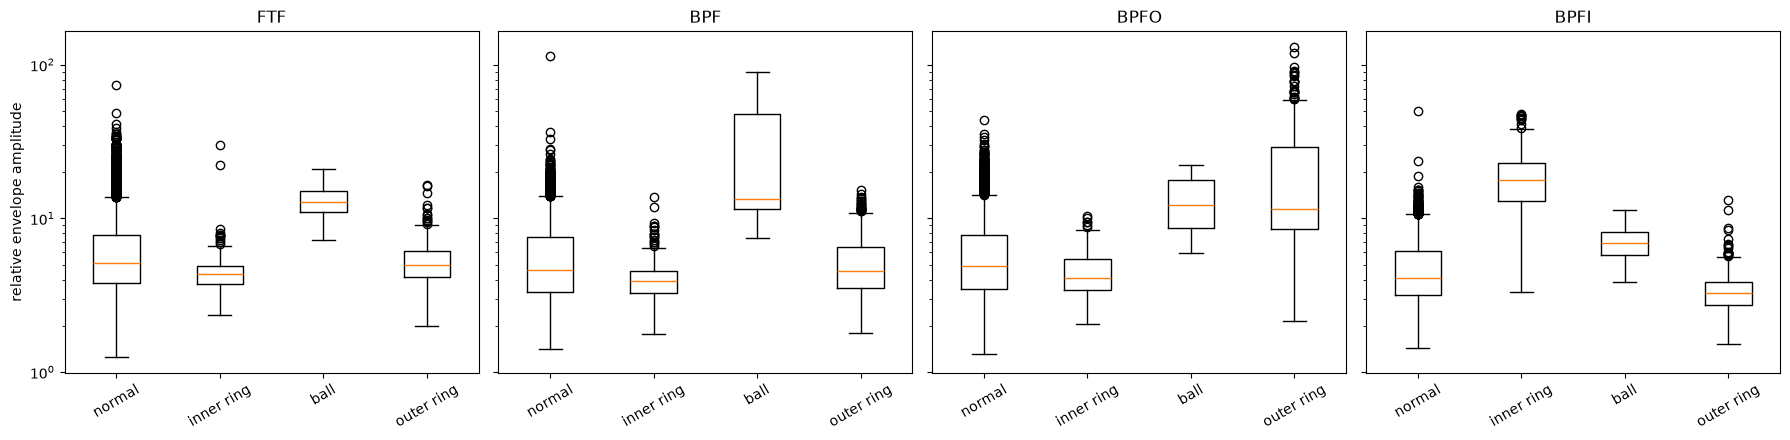

In [9]:
running = sca[sca["rpm"] > 0]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, fault in zip(axes, ["FTF", "BPF", "BPFO", "BPFI"]):
    data = [running.loc[running["label"] == label, f"vibration_fault_{fault}"].dropna() for label in [0, 1, 2, 3]]
    ax.boxplot(data, tick_labels=[label_names[label] for label in [0, 1, 2, 3]])
    ax.set_title(fault)
    ax.set_yscale("log")
    ax.tick_params(axis="x", labelrotation=30)
axes[0].set_ylabel("relative envelope amplitude")
plt.tight_layout()

### SCA median fault features per label

In [10]:
fault_columns = [f"vibration_fault_{n}" for n in ["FTF", "BPF", "BPFO", "BPFI"]]
running.groupby("label")[fault_columns].median().rename(index=label_names).round(2)

,vibration_fault_FTF,vibration_fault_BPF,vibration_fault_BPFO,vibration_fault_BPFI
label,,,,
off or no speed,5.31,2.92,2.97,2.75
normal,5.16,4.64,4.90,4.09
inner ring,4.33,3.89,4.08,17.89
ball,12.75,13.29,12.16,6.92
outer ring,5.01,4.54,11.59,3.28


### SCA fault feature over time per case

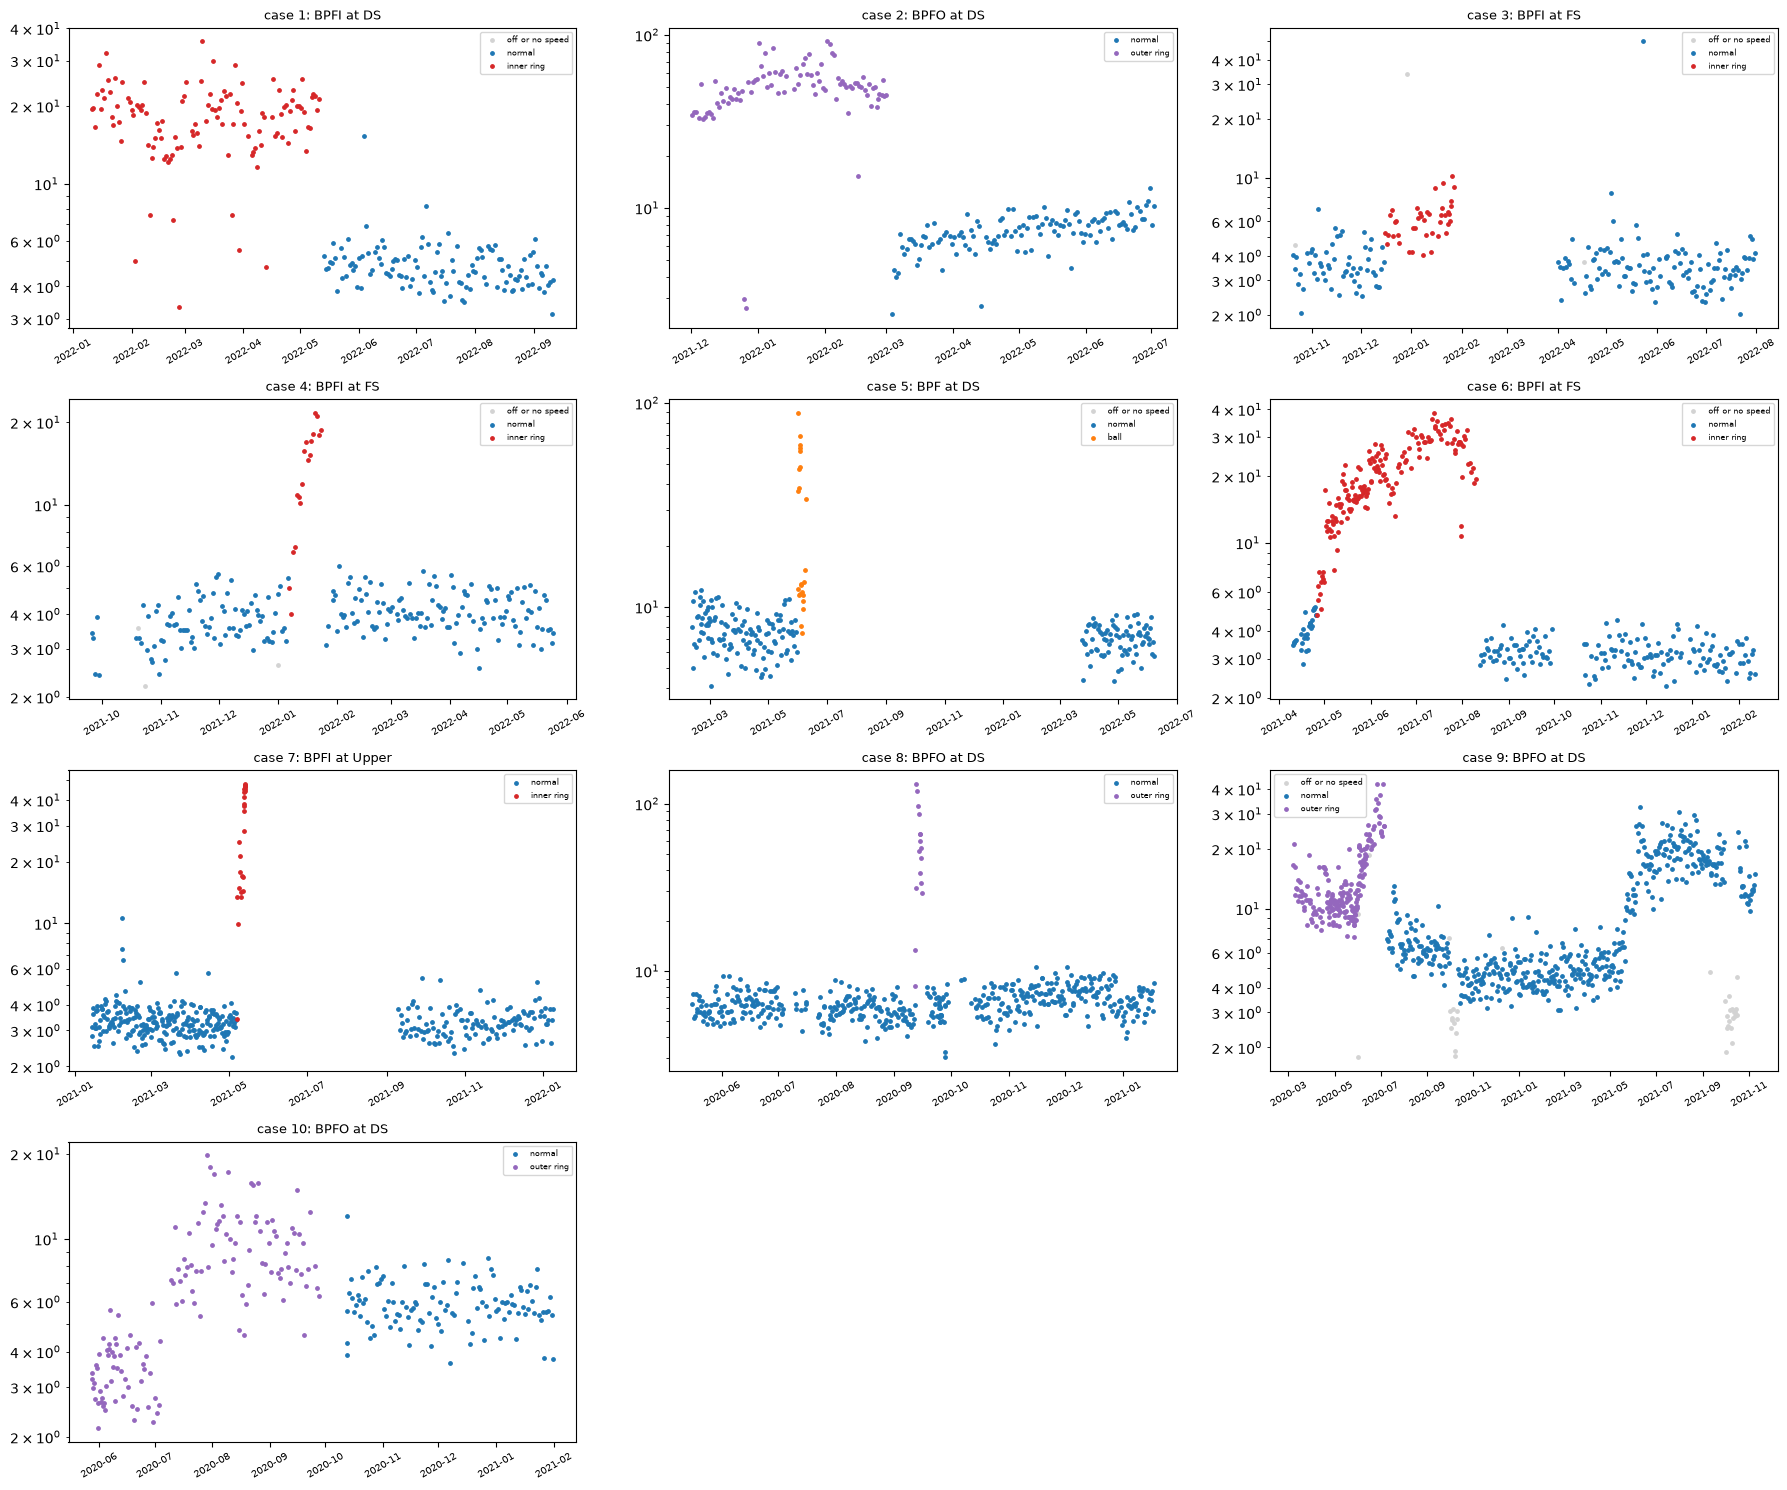

In [11]:
# The feature that matches each case's fault type: inner ring -> BPFI, ball -> BPF, outer ring -> BPFO.
fault_feature = {1: "BPFI", 2: "BPF", 3: "BPFO"}
colors = {-1: "lightgray", 0: "tab:blue", 1: "tab:red", 2: "tab:orange", 3: "tab:purple"}
cases = [c for c in sorted(sca["case"].unique()) if (sca.loc[sca["case"] == c, "label"] > 0).any()]

fig, axes = plt.subplots(4, 3, figsize=(18, 15))
for ax, case in zip(axes.flat, cases):
    g = sca[(sca["case"] == case) & (sca["placement"].str.lower() == sca["fault_origin"].str.lower())]
    if g.empty:
        g = sca[sca["case"] == case]
    fault = fault_feature[int(g["label"].max())]
    for label, gl in g.groupby("label"):
        ax.scatter(gl["time"], gl[f"vibration_fault_{fault}"], s=6, color=colors[label], label=label_names[label])
    ax.set_title(f"case {case}: {fault} at {g['placement'].iat[0]}", fontsize=9)
    ax.set_yscale("log")
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
    ax.legend(fontsize=6)
for ax in axes.flat[len(cases):]:
    ax.axis("off")
plt.tight_layout()

### SCA case 11 external event

In [12]:
case11 = sca[(sca["case"] == 11) & (sca["rpm"] > 0)]
case11.groupby(["part", "placement"])[
    ["vibration_rms", "vibration_kurtosis", "vibration_fault_BPFO", "vibration_fault_BPFI"]
].median().round(3)

vibration_rms  vibration_kurtosis  vibration_fault_BPFO  \
part  placement                                                            
test  DS                 2.111               2.802                 3.488   
      FS                 2.166               3.140                 3.540   
train DS                 1.303               2.936                 3.701   
      FS                 1.758               2.981                 5.792   

                 vibration_fault_BPFI  
part  placement                        
test  DS                        3.395  
      FS                        3.387  
train DS                        3.655  
      FS                        5.392

## Questions to answer from these results

- FEMTO: which features have a high correlation with the fraction of life in every bearing, not just on average?
- FEMTO: do recordings at 48.15 g form a separate group in the peak and flat-top plot?
- IMS: do the failed bearings separate from the healthy ones before the last day of each test?
- SCA: does each fault type have the highest median in its own fault feature?
- SCA: how early before the bearing change does the matching fault feature rise in each case?
- SCA case 11: do the features of the external event look like a bearing fault? If so, that's a false alarm risk for Phase 4.